<a href="https://colab.research.google.com/github/marinaalfarias/ia940/blob/main/Aula10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 10 — O que é estar perto?

**IA/EG940 · 2s2026**

Até aqui, você descreveu sons com espectrogramas e descritores. A partir desta aula, cada som vira **um vetor**, e "parecido" passa a significar "perto". Hoje vamos testar até onde essa ideia funciona — e onde ela quebra.

Todos os sons deste notebook são **sintetizados**: assim sabemos exatamente o que há neles. Em vários exercícios aparece **Previsão**. Faça uma cópia deste notebook na sua conta (*Arquivo → Salvar uma cópia no Drive*) e escreva sua resposta na célula livre *antes* de rodar a célula correspondente. Errar a previsão faz parte; o que importa é explicar depois por que errou.

In [ ]:
# Configuração (rode uma vez)
import numpy as np
import matplotlib.pyplot as plt
import librosa
from IPython.display import Audio, display
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

SR = 22050
rng = np.random.default_rng(10)
plt.rcParams['figure.figsize'] = (9, 3.5)

def ouvir(x, sr=SR):
    display(Audio(x, rate=sr))

### Ferramentas de síntese

Você não precisa ler esta célula em detalhe. Ela define três geradores de som: `tom` (série harmônica filtrada por formantes, como na síntese aditiva da Aula 6), `ruido` (ruído branco filtrado pelos mesmos formantes) e `pios` (sequência de varreduras de frequência, um "pássaro" sintético).

In [ ]:
def ganho_formantes(f, formantes):
    # Envoltória espectral: soma de ressonâncias (fc, largura de banda), em Hz
    g = np.full_like(np.asarray(f, float), 1e-3)
    for fc, bw in formantes:
        g = g + 1 / (1 + ((f - fc) / (bw / 2))**2)
    return g

def envoltoria(n, ataque=0.05, decaimento=2.0):
    t = np.arange(n) / SR
    return np.minimum(t / ataque, 1) * np.exp(-t / decaimento)

def normaliza(x):
    return 0.5 * x / np.max(np.abs(x))

def tom(f0, formantes, dur=1.0, ataque=0.05, decaimento=2.0):
    n = int(dur * SR); t = np.arange(n) / SR; x = np.zeros(n)
    for k in range(1, int(SR / 2 / f0)):
        x += ganho_formantes(k * f0, formantes) * np.sin(2*np.pi*k*f0*t + rng.uniform(0, 2*np.pi))
    return normaliza(x * envoltoria(n, ataque, decaimento))

def ruido(formantes, dur=1.0, ataque=0.05, decaimento=2.0):
    n = int(dur * SR)
    X = np.fft.rfft(rng.standard_normal(n)); f = np.fft.rfftfreq(n, 1/SR)
    x = np.fft.irfft(X * ganho_formantes(f, formantes), n)
    return normaliza(x * envoltoria(n, ataque, decaimento))

def pios(dur=1.0):
    n = int(dur * SR); x = np.zeros(n)
    n_pios = rng.integers(2, 6); fb = rng.uniform(1500, 4500); L = int(rng.uniform(0.06, 0.18) * SR)
    for i in range(n_pios):
        ini = int(i * n / n_pios + rng.uniform(0, 0.05) * SR)
        if ini + L > n: break
        t = np.arange(L) / SR
        f = fb + rng.uniform(-1500, 1500) * t / t[-1]
        x[ini:ini+L] += np.sin(2*np.pi*np.cumsum(f)/SR) * np.hanning(L)
    return normaliza(x)

def com_ruido(x, snr_db):
    r = rng.standard_normal(len(x))
    r *= np.sqrt(np.mean(x**2) / np.mean(r**2) / 10**(snr_db/10))
    return x + r

---
## Exercício 1 — O ouvido contra a régua

### 1a. Ouça

Ouça os três sons abaixo.

**Previsão:** qual par é o mais parecido — A–B, A–C ou B–C? E qual é o mais diferente?

✏️ **Sua previsão:** *(clique duas vezes para escrever, antes de rodar a próxima célula)*

In [ ]:
E1 = [(500, 150), (1500, 200), (2500, 250)]     # envoltória espectral 1
E2 = [(250, 100), (4000, 400), (7000, 600)]     # envoltória espectral 2

A = com_ruido(tom(220, E1), 40)
B = com_ruido(tom(220, E2), 40)
C = ruido(E1)

for nome, x in zip('ABC', (A, B, C)):
    print('Som', nome); ouvir(x)

### 1b. Do som ao vetor

Primeiro, o espectro médio de cada som, com a envoltória de formantes usada para sintetizá-lo (linhas vermelhas: frequências centrais dos formantes). Depois, o mel-espectrograma.

O mel-espectrograma agrupa as raias da STFT em faixas de largura crescente com a frequência — a mesma ideia das bandas críticas da Aula 4. Os MFCCs são a DCT do mel-espectrograma em dB: um cepstro (Aula 5) na escala mel. Os primeiros coeficientes descrevem a forma geral da envoltória espectral.

Para transformar um som inteiro em **um único vetor**, tiramos a média de cada coeficiente ao longo do tempo. Descartamos o coeficiente 0, que mede basicamente a energia total.

In [ ]:
# O que há em cada som: espectro médio (Welch) e a envoltória de formantes usada na síntese
from scipy.signal import welch

fig, eixos = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, nome, x, E in zip(eixos, 'ABC', (A, B, C), (E1, E2, E1)):
    f, P = welch(x, fs=SR, nperseg=4096)
    P_db = 10 * np.log10(P + 1e-12)
    G_db = 20 * np.log10(ganho_formantes(f, E))
    ax.plot(f, P_db - P_db.max(), lw=0.6, label='espectro do som')
    ax.plot(f, G_db - G_db.max(), 'k--', lw=1.2, label='envoltória (formantes)')
    for fc, _ in E:
        ax.axvline(fc, color='r', lw=0.6, alpha=0.5)
    ax.set_xlim(0, 8000); ax.set_ylim(-90, 5)
    ax.set_title(f'Som {nome}'); ax.set_xlabel('frequência (Hz)')
eixos[0].set_ylabel('dB (rel. ao máximo)'); eixos[0].legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()

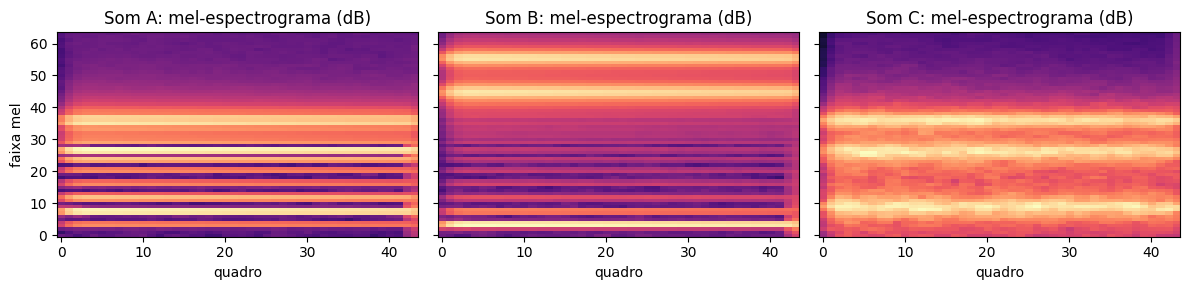

Dimensão de cada vetor: (12,)
vA = [ 32.4 -77.5  21.1  18.3 -25.4 -18.1 -12.9 -26.3 -13.8   9.2  -2.9 -22.3]


In [ ]:
def mel_db(x):
    return librosa.power_to_db(librosa.feature.melspectrogram(y=x, sr=SR, n_mels=64), ref=np.max)

fig, eixos = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, nome, x in zip(eixos, 'ABC', (A, B, C)):
    ax.imshow(mel_db(x), origin='lower', aspect='auto', cmap='magma', vmin=-80, vmax=0)
    ax.set_title(f'Som {nome}: mel-espectrograma (dB)'); ax.set_xlabel('quadro')
eixos[0].set_ylabel('faixa mel')
plt.tight_layout(); plt.show()

def vetor_mfcc(x, n_mfcc=13):
    M = librosa.feature.mfcc(y=x, sr=SR, n_mfcc=n_mfcc)   # (n_mfcc, quadros)
    return M[1:].mean(axis=1)                              # média no tempo, sem o coeficiente 0

vA, vB, vC = vetor_mfcc(A), vetor_mfcc(B), vetor_mfcc(C)
print('Dimensão de cada vetor:', vA.shape)
print('vA =', np.round(vA, 1))

### 1c. Meça

Duas réguas comuns entre vetores $\mathbf{u}$ e $\mathbf{v}$:

$$d_{\text{euclid}}(\mathbf{u},\mathbf{v}) = \sqrt{\sum_i (u_i - v_i)^2} \qquad\qquad d_{\cos}(\mathbf{u},\mathbf{v}) = 1 - \frac{\mathbf{u}\cdot\mathbf{v}}{\|\mathbf{u}\|\,\|\mathbf{v}\|}$$

A distância euclidiana mede o comprimento do segmento entre os dois pontos. A distância cosseno ignora o comprimento dos vetores e compara apenas a direção.

In [ ]:
def d_euclid(u, v): return np.linalg.norm(u - v)
def d_cos(u, v):    return 1 - u @ v / (np.linalg.norm(u) * np.linalg.norm(v))

for (n1, u), (n2, v) in [(('A', vA), ('B', vB)), (('A', vA), ('C', vC)), (('B', vB), ('C', vC))]:
    print(f'{n1}–{n2}:  euclidiana = {d_euclid(u, v):6.1f}    cosseno = {d_cos(u, v):.3f}')

A–B:  euclidiana =  204.3    cosseno = 1.403
A–C:  euclidiana =  120.3    cosseno = 0.158
B–C:  euclidiana =  307.1    cosseno = 1.691


**Para discutir:** a régua concordou com o seu ouvido? O que o vetor de MFCCs médios "enxerga" desses sons, e o que ele ignora? Olhe de novo os mel-espectrogramas.

---
## Uma base de dados sintética

Para os próximos exercícios, geramos 40 exemplos de cada uma de três classes, com parâmetros sorteados e ruído de fundo com SNR entre 0 e 20 dB:

- **0 — tonal:** tons harmônicos com altura, formantes e envoltória sorteados;
- **1 — percussivo:** rajadas de ruído filtrado, com ataque rápido e decaimento curto;
- **2 — pios:** sequências de varreduras de frequência.

In [ ]:
E_base = [(500, 150), (1500, 200), (2500, 250)]
NOMES = ['tonal', 'percussivo', 'pios']

def exemplo(classe):
    if classe == 0:
        e = rng.uniform(0.6, 1.6)
        x = tom(rng.uniform(110, 660), [(fc*e, bw*e) for fc, bw in E_base],
                ataque=rng.uniform(0.03, 0.3), decaimento=rng.uniform(0.8, 3))
    elif classe == 1:
        e = rng.uniform(0.4, 3)
        x = ruido([(fc*e, bw*e) for fc, bw in E_base], ataque=0.002, decaimento=rng.uniform(0.03, 0.25))
    else:
        x = pios()
    return com_ruido(x, rng.uniform(0, 20))

y = np.repeat([0, 1, 2], 40)
sons = [exemplo(c) for c in y]

MF = np.array([vetor_mfcc(x) for x in sons])   # vetores de MFCCs médios (12 dimensões)

for c in range(3):
    print(NOMES[c]); ouvir(sons[np.where(y == c)[0][0]])

tonal


percussivo


pios


---
## Exercício 2 — Quem manda na distância?

Vamos descrever cada som por apenas três números: o **centroide espectral** (em Hz), a **taxa de cruzamentos por zero** (ZCR, uma fração entre 0 e 1) e o **RMS** (amplitude eficaz). Todos são médias ao longo do tempo.

In [ ]:
def descritores(x):
    return [librosa.feature.spectral_centroid(y=x, sr=SR).mean(),
            librosa.feature.zero_crossing_rate(x).mean(),
            librosa.feature.rms(y=x).mean()]

NOMES_DESC = ['centroide (Hz)', 'ZCR', 'RMS']
D = np.array([descritores(x) for x in sons])
for j, nome in enumerate(NOMES_DESC):
    print(f'{nome:15s}  mín = {D[:, j].min():9.3f}   máx = {D[:, j].max():9.3f}')

centroide (Hz)   mín =  3419.625   máx =  5445.679
ZCR              mín =     0.041   máx =     0.478
RMS              mín =     0.010   máx =     0.252


**Previsão:** se calcularmos a distância euclidiana entre dois sons usando esses três números crus, qual descritor vai pesar mais? Que acurácia você espera de um kNN treinado assim?

✏️ **Sua previsão:** *(clique duas vezes para escrever, antes de rodar a próxima célula)*

In [ ]:
def contribuicao(F):
    # Fração média do quadrado da distância que vem de cada descritor, entre pares de sons
    i, j = rng.integers(0, len(F), (2, 2000))
    dif2 = (F[i] - F[j])**2
    return dif2.mean(axis=0) / dif2.sum(axis=1).mean()

def acuracia_knn(F, k=5, normalizar=True, repeticoes=10):
    acc = []
    for s in range(repeticoes):
        Ftr, Fte, ytr, yte = train_test_split(F, y, test_size=0.3, stratify=y, random_state=s)
        if normalizar:
            sc = StandardScaler().fit(Ftr)          # média e desvio estimados só no treino
            Ftr, Fte = sc.transform(Ftr), sc.transform(Fte)
        acc.append(KNeighborsClassifier(n_neighbors=k).fit(Ftr, ytr).score(Fte, yte))
    return np.mean(acc)

print('Contribuição de cada descritor para d²:', np.round(contribuicao(D), 4))
print(f'Acurácia kNN (k=5), descritores crus: {acuracia_knn(D, normalizar=False):.0%}')

Contribuição de cada descritor para d²: [1. 0. 0.]
Acurácia kNN (k=5), descritores crus: 42%


### 2b. Padronização (z-score)

Cada descritor $j$ passa a ser medido em "desvios-padrão a partir da média":

$$z_j = \frac{x_j - \mu_j}{\sigma_j}$$

com $\mu_j$ e $\sigma_j$ estimados **apenas no conjunto de treino**.

**Previsão:** o que muda na contribuição de cada descritor? E na acurácia?

✏️ **Sua previsão:** *(clique duas vezes para escrever, antes de rodar a próxima célula)*

In [ ]:
Z = StandardScaler().fit_transform(D)
print('Contribuição após o z-score:', np.round(contribuicao(Z), 3))
print(f'Acurácia kNN (k=5), descritores padronizados: {acuracia_knn(D, normalizar=True):.0%}')

Contribuição após o z-score: [0.343 0.335 0.321]
Acurácia kNN (k=5), descritores padronizados: 93%


**Para discutir:** o centroide é um descritor ruim? Por que estimamos $\mu$ e $\sigma$ só no treino, e não na base inteira?

---
## Exercício 3 — A forma da vizinhança

O kNN classifica um ponto novo pelo **voto da maioria entre os $k$ vizinhos mais próximos** no treino. Não há "treinamento" além de guardar os exemplos.

Para enxergar o que isso significa, usamos só duas dimensões do vetor de MFCCs médios (coeficientes 1 e 3), padronizadas, e pintamos o plano com a classe que o kNN atribuiria a cada ponto.

**Previsão:** como você espera que a fronteira de decisão mude de $k=1$ para $k=31$? Com $k=1$, qual será a acurácia **no próprio treino**?

✏️ **Sua previsão:** *(clique duas vezes para escrever, antes de rodar a próxima célula)*

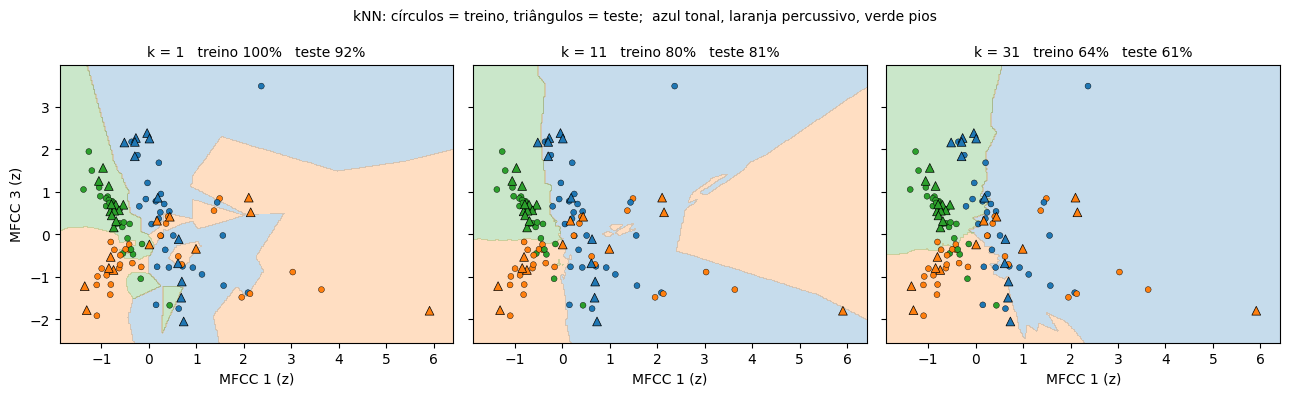

In [ ]:
F2 = MF[:, [0, 2]]                                  # MFCC 1 e MFCC 3
F2tr, F2te, ytr, yte = train_test_split(F2, y, test_size=0.3, stratify=y, random_state=0)
sc2 = StandardScaler().fit(F2tr)
F2tr, F2te = sc2.transform(F2tr), sc2.transform(F2te)

lo, hi = np.vstack([F2tr, F2te]).min(0) - 0.5, np.vstack([F2tr, F2te]).max(0) + 0.5
xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], 300), np.linspace(lo[1], hi[1], 300))
grade = np.c_[xx.ravel(), yy.ravel()]
CORES = np.array(['#1f77b4', '#ff7f0e', '#2ca02c'])

def mapa(ax, modelo, titulo):
    zz = modelo.predict(grade).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], colors=CORES, alpha=0.25)
    ax.scatter(*F2tr.T, c=CORES[ytr], s=18, edgecolor='k', linewidth=0.3)
    ax.scatter(*F2te.T, c=CORES[yte], s=40, marker='^', edgecolor='k', linewidth=0.5)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel('MFCC 1 (z)')

fig, eixos = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, k in zip(eixos, [1, 11, 31]):
    m = KNeighborsClassifier(n_neighbors=k).fit(F2tr, ytr)
    mapa(ax, m, f'k = {k}   treino {m.score(F2tr, ytr):.0%}   teste {m.score(F2te, yte):.0%}')
eixos[0].set_ylabel('MFCC 3 (z)')
fig.suptitle('kNN: círculos = treino, triângulos = teste;  azul tonal, laranja percussivo, verde pios', fontsize=10)
plt.tight_layout(); plt.show()

**Para discutir:** o mapa de $k=1$ tem "ilhas" de uma classe dentro da região de outra: ele decorou o treino. Mesmo assim, a acurácia de teste de $k=1$ pode ter saído **maior** que a dos outros. Como isso é possível?

### 3b. Uma divisão só não basta

Os números acima vêm de **uma única** divisão treino/teste, com 36 exemplos de teste: cada exemplo vale quase 3 pontos percentuais. Vamos repetir a divisão 50 vezes e olhar a média e a dispersão para cada $k$.

**Previsão:** como serão as curvas de acurácia de treino e de teste em função de $k$?

✏️ **Sua previsão:** *(clique duas vezes para escrever, antes de rodar a próxima célula)*

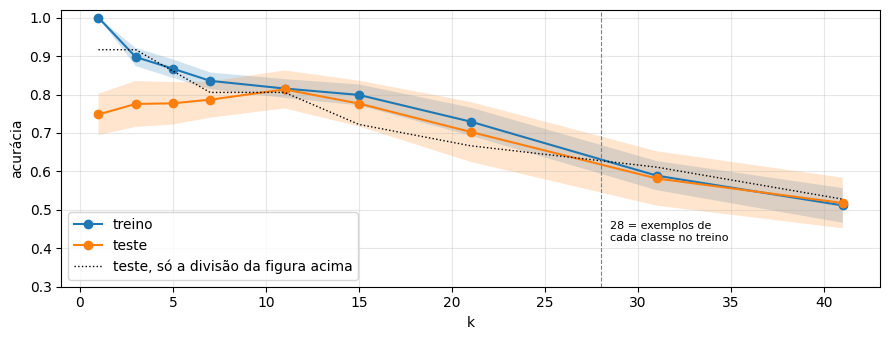

In [ ]:
ks = [1, 3, 5, 7, 11, 15, 21, 31, 41]
acc_tr, acc_te = np.zeros((len(ks), 50)), np.zeros((len(ks), 50))
for s in range(50):
    a, b, ya, yb = train_test_split(F2, y, test_size=0.3, stratify=y, random_state=s)
    sc = StandardScaler().fit(a); a, b = sc.transform(a), sc.transform(b)
    for i, k in enumerate(ks):
        m = KNeighborsClassifier(n_neighbors=k).fit(a, ya)
        acc_tr[i, s], acc_te[i, s] = m.score(a, ya), m.score(b, yb)

for nome, A_ in [('treino', acc_tr), ('teste', acc_te)]:
    plt.plot(ks, A_.mean(1), 'o-', label=nome)
    plt.fill_between(ks, A_.mean(1) - A_.std(1), A_.mean(1) + A_.std(1), alpha=0.2)
plt.plot(ks, acc_te[:, 0], 'k:', lw=1, label='teste, só a divisão da figura acima')
plt.axvline(28, color='gray', lw=0.8, ls='--')
plt.text(28.5, 0.42, '28 = exemplos de\ncada classe no treino', fontsize=8)
plt.xlabel('k'); plt.ylabel('acurácia'); plt.ylim(0.3, 1.02)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Para discutir:** qual valor de $k$ você escolheria agora, e com base em quê? Por que a acurácia despenca quando $k$ se aproxima de 28? No projeto, cada ponto da curva será repetido com pelo menos dez divisões pelo mesmo motivo.

### 3c. Um contraste: a SVM

A SVM, vista no seminário, também separa classes no plano, mas de outra forma: ela procura a fronteira que deixa a **maior margem** possível até os exemplos mais próximos de cada classe, e depois descarta todos os outros exemplos. Com núcleo RBF, essa fronteira pode ser curva.

**Previsão:** a fronteira da SVM vai parecer mais com a do kNN com $k=1$ ou com $k=31$?

✏️ **Sua previsão:** *(clique duas vezes para escrever, antes de rodar a próxima célula)*

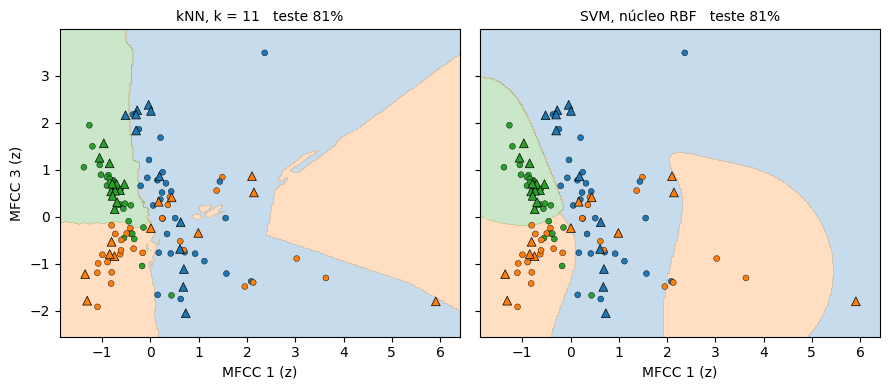

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, (nome, m) in zip(eixos, [('kNN, k = 11', KNeighborsClassifier(11)),
                                 ('SVM, núcleo RBF', SVC(kernel='rbf', C=1))]):
    m.fit(F2tr, ytr)
    mapa(ax, m, f'{nome}   teste {m.score(F2te, yte):.0%}')
eixos[0].set_ylabel('MFCC 3 (z)')
plt.tight_layout(); plt.show()

**Para discutir:** o kNN guarda todos os exemplos; a SVM guarda só alguns. Qual dos dois você usaria se a base de dados ganhasse um exemplo novo a cada dia? E se ela tivesse um milhão de exemplos?

---
## Exercício 4 — A maldição da dimensionalidade

Os embeddings que vocês vão usar no projeto têm de 128 a 1024 dimensões. Será que "perto" ainda significa alguma coisa nesses espaços?

### 4a. Pontos ao acaso

Sorteamos 500 pontos uniformemente num hipercubo de dimensão $d$ e medimos, a partir de um ponto de consulta, a distância ao vizinho **mais próximo** e ao **mais distante**.

**Previsão:** o que acontece com a razão $d_{\max}/d_{\min}$ quando $d$ cresce de 2 para 1000?

✏️ **Sua previsão:** *(clique duas vezes para escrever, antes de rodar a próxima célula)*

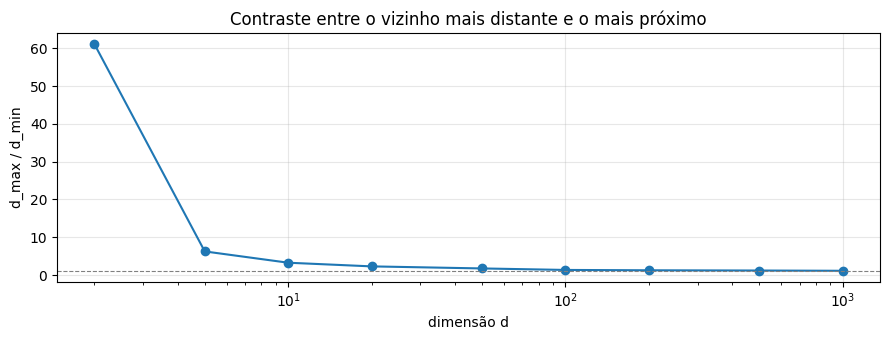

In [ ]:
dims = [2, 5, 10, 20, 50, 100, 200, 500, 1000]
razoes = []
for d in dims:
    P = rng.uniform(size=(500, d)); q = rng.uniform(size=d)
    dist = np.linalg.norm(P - q, axis=1)
    razoes.append(dist.max() / dist.min())

plt.semilogx(dims, razoes, 'o-')
plt.axhline(1, color='gray', lw=0.8, ls='--')
plt.xlabel('dimensão d'); plt.ylabel('d_max / d_min')
plt.title('Contraste entre o vizinho mais distante e o mais próximo')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 4b. Dimensões que não dizem nada

Agora voltamos aos MFCCs dos nossos sons (12 dimensões úteis) e acrescentamos $N$ dimensões de puro ruído, que não carregam informação nenhuma sobre a classe.

**Previsão:** a partir de quantas dimensões extras o kNN começa a falhar?

✏️ **Sua previsão:** *(clique duas vezes para escrever, antes de rodar a próxima célula)*

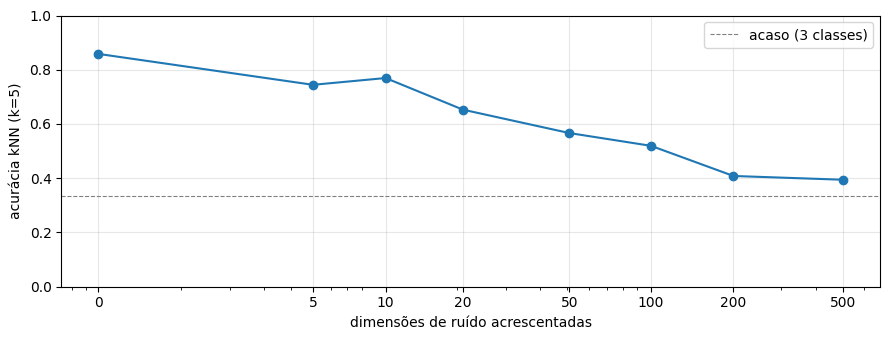

In [ ]:
extras = [0, 5, 10, 20, 50, 100, 200, 500]
acc = []
for N in extras:
    F = np.hstack([MF, rng.standard_normal((len(y), N)) * MF.std()]) if N else MF
    acc.append(acuracia_knn(F))

plt.semilogx(np.array(extras) + 1, acc, 'o-')
plt.axhline(1/3, color='gray', lw=0.8, ls='--', label='acaso (3 classes)')
plt.xticks(np.array(extras) + 1, extras)
plt.xlabel('dimensões de ruído acrescentadas'); plt.ylabel('acurácia kNN (k=5)')
plt.ylim(0, 1); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Para discutir:** se distâncias perdem o sentido em alta dimensão, por que um kNN sobre embeddings de 1024 dimensões ainda funciona? Pense na diferença entre "1024 dimensões independentes" e "1024 números que descrevem o mesmo som".

---
## Exercício 5 — O que a média esconde

Pegamos um som percussivo, o invertemos no tempo e geramos **outra realização** do mesmo golpe (mesmos parâmetros, outro sorteio de ruído).

**Previsão:** ordene os dois pares, do mais próximo ao mais distante: golpe–invertido e golpe–outro golpe.

✏️ **Sua previsão:** *(clique duas vezes para escrever, antes de rodar a próxima célula)*

In [ ]:
golpe = com_ruido(ruido(E_base, ataque=0.002, decaimento=0.15), 30)
invertido = golpe[::-1]
outro_golpe = com_ruido(ruido(E_base, ataque=0.002, decaimento=0.15), 30)

for nome, x in [('Golpe', golpe), ('Invertido', invertido), ('Outro golpe', outro_golpe)]:
    print(nome); ouvir(x)

Golpe


Invertido


Outro golpe


In [ ]:
def vetor_media_desvio(x):
    M = librosa.feature.mfcc(y=x, sr=SR, n_mfcc=13)[1:]
    return np.concatenate([M.mean(axis=1), M.std(axis=1)])

def compara(vetor):
    for nome, x in [('invertido', invertido), ('outro golpe', outro_golpe)]:
        print(f'   golpe – {nome:12s} {d_euclid(vetor(golpe), vetor(x)):6.2f}')

print('MFCC médio:');          compara(vetor_mfcc)
print('MFCC médio + desvio:'); compara(vetor_media_desvio)

MFCC médio:
   golpe – invertido      0.27
   golpe – outro golpe    3.62
MFCC médio + desvio:
   golpe – invertido      0.29
   golpe – outro golpe    4.33


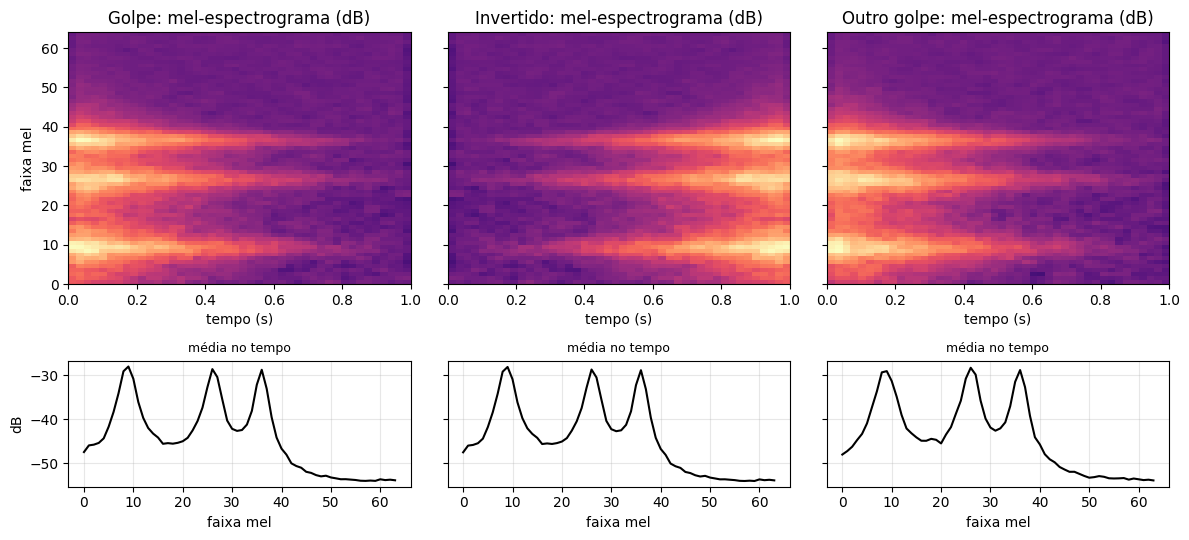

In [ ]:
# Espectrogramas dos três golpes e o que sobra deles na média temporal
sons_golpe = [('Golpe', golpe), ('Invertido', invertido), ('Outro golpe', outro_golpe)]
dur = len(golpe) / SR

fig, eixos = plt.subplots(2, 3, figsize=(12, 5.5), sharey='row',
                          gridspec_kw={'height_ratios': [2, 1]})
for j, (nome, x) in enumerate(sons_golpe):
    S = mel_db(x)
    eixos[0, j].imshow(S, origin='lower', aspect='auto', cmap='magma', vmin=-80, vmax=0,
                       extent=[0, dur, 0, S.shape[0]])
    eixos[0, j].set_title(f'{nome}: mel-espectrograma (dB)'); eixos[0, j].set_xlabel('tempo (s)')
    eixos[1, j].plot(S.mean(axis=1), 'k')
    eixos[1, j].set_xlabel('faixa mel'); eixos[1, j].set_title('média no tempo', fontsize=9)
    eixos[1, j].grid(alpha=0.3)
eixos[0, 0].set_ylabel('faixa mel'); eixos[1, 0].set_ylabel('dB')
plt.tight_layout(); plt.show()

**Para discutir:**

- Por que o invertido fica mais perto do golpe do que outra realização do próprio golpe, se para o ouvido é o contrário?
- Proponha uma modificação do vetor que afaste o invertido **sem** afastar o outro golpe. Implemente-a na célula abaixo e teste.
- O fingerprinting acústico (seminário) guarda a estrutura temporal: ele registra pares de picos do espectrograma e o intervalo de tempo entre eles. Por que essa representação serve para encontrar **a mesma gravação**, mas não um **som parecido**?

In [ ]:
# Sua proposta de vetor que preserve alguma informação temporal:
def meu_vetor(x):
    M = librosa.feature.mfcc(y=x, sr=SR, n_mfcc=13)[1:]
    # ... complete aqui ...
    return M.mean(axis=1)

print('Seu vetor:'); compara(meu_vetor)

Seu vetor:
   golpe – invertido      0.27
   golpe – outro golpe    3.62


---
## Da aula ao projeto

Hoje o vetor de cada som foi **projetado por nós**: escolhemos MFCCs, médias e desvios. No projeto, esse vetor (o MFCC médio) enfrenta um vetor **aprendido** por uma rede treinada com milhões de sons (o YAMNet), com o mesmo kNN. Cada ferramenta de hoje reaparece lá:

- **Ex. 1:** o MFCC médio enxerga a envoltória espectral. Que degradação da sua trilha mexe na envoltória, e qual não mexe? A resposta é a base da sua previsão.
- **Ex. 2:** o z-score, com média e desvio estimados só no treino, faz parte da tarefa do projeto.
- **Ex. 3b:** uma divisão treino/teste engana. Cada ponto da curva do projeto será repetido com pelo menos dez divisões.
- **Ex. 4b:** já foi uma curva de acurácia contra degradação, com dimensões de ruído. No projeto, a degradação é feita por DSP: distância, reverberação, transposição ou SNR.
- **Ex. 5:** uma distância só tem sentido diante de uma escala de referência. A diferença entre as duas curvas do projeto só conta se for maior que a dispersão.

Na próxima aula, abrimos a caixa: como uma rede aprende, sozinha, o que guardar e o que descartar?

**Para 23/10:** banco de dados escolhido e **previsão registrada** (esboço à mão das duas curvas, com justificativa acústica).